7.7
LSTM forecasting
Max score: 1
1. Build and evaluate a Long Short-Term Memory (LSTM) neural network to forecast future values of a time series dataset.
Choose a univariate or multivariate time series dataset (e.g., stock prices, energy consumption, weather data). Ensure the dataset has sufficient observations (at least 500 data points for meaningful training).
2. Handle missing values and normalize/scale the data (e.g., MinMaxScaler). Split the data into training, validation, and test sets.
3. Implement an LSTM-based architecture using a deep learning framework (TensorFlow/Keras or PyTorch). Experiment with hyperparameters (number of units, batch size, epochs).
4. Train the model on the training set and validate on the validation set.  Evaluate performance on the test set using metrics such as RMSE, MAE, and MAPE.
Compare predictions with actual values.
5. Plot original time series and actual vs predicted values for the test set
6. Interpret the results and discuss how well the model captures trends and seasonality

In [4]:
#Solution:

#Req. 1: Downloading Bitcoin stock price from 2020 to 2026

!pip install yfinance

import yfinance as yf

df = yf.download(
    "BTC-USD",
    start="2020-01-01",
    end="2026-08-01"
)

df.to_csv(r"S:\Python_Selfstudy\BTC-USD.csv")
print(df.head())



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open       Volume
Ticker          BTC-USD      BTC-USD      BTC-USD      BTC-USD      BTC-USD
Date                                                                       
2020-01-01  7200.174316  7254.330566  7174.944336  7194.892090  18565664997
2020-01-02  6985.470215  7212.155273  6935.270020  7202.551270  20802083465
2020-01-03  7344.884277  7413.715332  6914.996094  6984.428711  28111481032
2020-01-04  7410.656738  7427.385742  7309.514160  7345.375488  18444271275
2020-01-05  7411.317383  7544.497070  7400.535645  7410.451660  19725074095


In [ ]:
#Req. 2 Handle missing values and normalize/scale the data (e.g., MinMaxScaler). Split the data into training, validation, and test sets.

import pandas as pd
import numpy as np

from sklearn.preprocessing import MinMaxScaler

# Load data
df = pd.read_csv("BTC-USD.csv")
print(df.head())


#Colum headers containing 3 cells, so we need to rename them to 1 cell each





# Convert Date column
    #df['Date'] = pd.to_datetime(df['Date'])

# Sort by date
    #df = df.sort_values('Date')

# Check missing values
    #print(df.isnull().sum())

# Handle missing values
    #df = df.fillna(method='ffill')

# Use Close price for forecasting
    #data = df[['Date', 'Close']].copy()

# Set date as index
    #data.set_index('Date', inplace=True)

    #print(data.head())

        Price             Close              High               Low  \
0      Ticker           BTC-USD           BTC-USD           BTC-USD   
1        Date               NaN               NaN               NaN   
2  2020-01-01  7200.17431640625  7254.33056640625   7174.9443359375   
3  2020-01-02  6985.47021484375   7212.1552734375  6935.27001953125   
4  2020-01-03  7344.88427734375  7413.71533203125     6914.99609375   

               Open       Volume  
0           BTC-USD      BTC-USD  
1               NaN          NaN  
2  7194.89208984375  18565664997  
3  7202.55126953125  20802083465  
4   6984.4287109375  28111481032  


In [6]:
#date formating

import pandas as pd

df = pd.read_csv(
    "BTC-USD.csv",
    skiprows=[1]  # skip the Ticker row
)

print(df.head())

        Price        Close         High          Low         Open  \
0        Date          NaN          NaN          NaN          NaN   
1  2020-01-01  7200.174316  7254.330566  7174.944336  7194.892090   
2  2020-01-02  6985.470215  7212.155273  6935.270020  7202.551270   
3  2020-01-03  7344.884277  7413.715332  6914.996094  6984.428711   
4  2020-01-04  7410.656738  7427.385742  7309.514160  7345.375488   

         Volume  
0           NaN  
1  1.856566e+10  
2  2.080208e+10  
3  2.811148e+10  
4  1.844427e+10  


In [7]:
#date formating 
# still the extra row

import pandas as pd

df = pd.read_csv("BTC-USD.csv", skiprows=[1])

# Remove the first row containing 'Date'
df = df.iloc[1:]

# Rename Price column to Date
df.rename(columns={"Price": "Date"}, inplace=True)

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Set Date as index
df.set_index("Date", inplace=True)

print(df.head())
print(df.info())

                  Close         High          Low         Open        Volume
Date                                                                        
2020-01-01  7200.174316  7254.330566  7174.944336  7194.892090  1.856566e+10
2020-01-02  6985.470215  7212.155273  6935.270020  7202.551270  2.080208e+10
2020-01-03  7344.884277  7413.715332  6914.996094  6984.428711  2.811148e+10
2020-01-04  7410.656738  7427.385742  7309.514160  7345.375488  1.844427e+10
2020-01-05  7411.317383  7544.497070  7400.535645  7410.451660  1.972507e+10
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2404 entries, 2020-01-01 to 2026-07-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2404 non-null   float64
 1   High    2404 non-null   float64
 2   Low     2404 non-null   float64
 3   Open    2404 non-null   float64
 4   Volume  2404 non-null   float64
dtypes: float64(5)
memory usage: 112.7 KB
None


In [ ]:
# checking the null values & good to see, there is no null values
print(df.isnull().sum())

Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [10]:
#normalize/scale the data (e.g., MinMaxScaler)
    #LSTM neural networks generally learn better when input values are in a small range, such as 0 to 1. Values are easier for the LSTM to process.

from sklearn.preprocessing import MinMaxScaler
    ### Scikit-Learn contains many ready-made machine learning tools.

close_data = df[["Close"]]
    ##We want a separate variable containing only the Close prices.

scaler = MinMaxScaler(feature_range=(0,1))
    ## Stores the MinMaxScaler object under name"scaler'
scaled_data = scaler.fit_transform(close_data)
    ##We need somewhere to keep the transformed data.
print(scaled_data[:5])





[[0.01861207]
 [0.01681961]
 [0.01982018]
 [0.02036929]
 [0.0203748 ]]


In [11]:
#Split the data into training, validation, and test sets.
#Reason: If you let the LSTM see all 2404 days during training, then later asking "How good are your predictions?" would be unfair because it has already seen everything.
#So, give the model some % of data and check how it performs(Training), is the model learning correctly(Validation) here actual data is hiding to the machine & after testing, Final and real TEST

# Calculate 70% of the data for training

train_size = int(len(scaled_data) * 0.70)
# len(scaled_data) gets total number of rows.
# * 0.70 means 70% of the data.
# int() converts the result to a whole number.

# Calculate 15% of the data for validation

val_size = int(len(scaled_data) * 0.15)
# We reserve 15% of the data for validation.
# Validation data helps check model performance while training.

# Create the training dataset

train_data = scaled_data[:train_size]
# Start from the first row and take data up to train_size.
# This data will be used to teach the LSTM model.

# Create the validation dataset

val_data = scaled_data[train_size:train_size+val_size]
# Start where training data ends.
# Take the next 15% of the data.
# This data is used to evaluate the model during training.

# Create the test dataset

test_data = scaled_data[train_size+val_size:]
# Start where validation data ends.
# Take all remaining rows.
# This data is kept unseen until the final evaluation.

# Print the number of rows in each dataset

print("Training samples:", len(train_data))
# Shows how many rows are in the training set.

print("Validation samples:", len(val_data))
# Shows how many rows are in the validation set.

print("Test samples:", len(test_data))
# Shows how many rows are in the test set.

Training samples: 1682
Validation samples: 360
Test samples: 362


Req. 3: Implement an LSTM-based architecture using TensorFlow/Keras or PyTorch. Experiment with hyperparameters (number of units, batch size, epochs).

So, after loading, cleaning, scalled and spilt data,
Now you need to create the brain that will learn Bitcoin price patterns.

That brain is the LSTM model. 
(Implement an LSTM-based architecture)

    LSTM = the machine (model)
    TensorFlow / Keras / PyTorch = the toolbox used to build the machine

    Hyperparameter:
        Units

        → Number of memory cells in LSTM.

        → More units = more learning capacity.

         

        Batch Size

        → Number of training samples processed at a time.

         

        Epochs

        → Number of times the model sees the entire training dataset.

In [12]:
#build the LSTM model.

from tensorflow.keras.models import Sequential
# Import Sequential, which allows us to build the neural network layer by layer.

from tensorflow.keras.layers import LSTM, Dense, Dropout
# Import the layers we need: LSTM for learning patterns, Dense for output, Dropout to reduce overfitting.

model = Sequential()
# Create an empty neural network model.

model.add(LSTM(64, return_sequences=True, input_shape=(60,1)))
# Add the first LSTM layer with 64 memory units, looking at 60 previous days and 1 feature (Close price).

model.add(Dropout(0.2))
# Randomly ignore 20% of neurons during training to help prevent overfitting.

model.add(LSTM(32))
# Add a second LSTM layer with 32 memory units to learn more complex patterns.

model.add(Dropout(0.2))
# Again ignore 20% of neurons during training.

model.add(Dense(1))
# Add the output layer that predicts one value: the next Close price.

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)
# Configure the model: Adam updates weights efficiently and MSE measures prediction error.

model.summary()
# Display the structure of the model.

c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

REQ: 4 Train the model on the training set and validate on the validation set.  Evaluate performance on the test set using metrics such as RMSE, MAE, and MAPE.
Compare predictions with actual values.


We just buit a model but it has no learn anything yet
    Use the training data to teach the LSTM model, while using the validation data to monitor whether the model is learning correctly and not overfitting.
        Overfitting means memorizing and give answer only when you see the same question in exam, NOT leanring the concept and solving accordingly
    
RMSE, MAE, and MAPE
    evaluation metrics used after training to measure how good your predictions are
    





In [14]:
#Training Steps

import numpy as np
# Import NumPy for working with arrays.

def create_dataset(data, time_step=60):
# Create a function to convert a time series into LSTM input-output sequences.

    X, y = [], []
# Create empty lists to store inputs (X) and target values (y).

    for i in range(len(data) - time_step):
# Loop through the dataset and create sequences of 60 days.

        X.append(data[i:(i + time_step), 0])
# Store the previous 60 days as one input sample.

        y.append(data[i + time_step, 0])
# Store the value immediately after those 60 days as the target.

    return np.array(X), np.array(y)
# Convert the lists into NumPy arrays and return them.


X_train, y_train = create_dataset(train_data)
# Create training inputs (X_train) and training targets (y_train).

X_val, y_val = create_dataset(val_data)
# Create validation inputs (X_val) and validation targets (y_val).

X_test, y_test = create_dataset(test_data)
# Create test inputs (X_test) and test targets (y_test).


X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
# Reshape training inputs into the format required by LSTM: (samples, time steps, features).

X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
# Reshape validation inputs into the format required by LSTM.

X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
# Reshape test inputs into the format required by LSTM.


print(X_train.shape)
# Display the shape of the training input data.

print(y_train.shape)
# Display the shape of the training target data.

print(X_val.shape)
# Display the shape of the validation input data.

print(y_val.shape)
# Display the shape of the validation target data.

history = model.fit(
# Start training the LSTM model and save the training history.

    X_train,
# Input data used for learning (previous 60-day sequences).

    y_train,
# Actual target values the model should predict.

    validation_data=(X_val, y_val),
# Use validation data to check performance on unseen data during training.

    epochs=20,
# Train using the entire training dataset 20 times.

    batch_size=32,
# Process 32 training samples at a time before updating weights.

    verbose=1
# Show training progress and results for each epoch.
)

(1622, 60, 1)
(1622,)
(300, 60, 1)
(300,)
Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 0.0128 - val_loss: 0.0064
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0016 - val_loss: 0.0017
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0016 - val_loss: 0.0022
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0014 - val_loss: 0.0016
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0013 - val_loss: 0.0046
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0014 - val_loss: 0.0020
Epoch 8/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0013 - val_loss: 0.0041
Epoch 9/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0013 - val_loss: 0.0016
Epoch 10/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0011 - val_loss: 0.0020
Epoch 11/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0011 - val_loss: 0.0038
Epoch 12/20
51/51 ━━━

In [15]:
#Evaluate performance on the test set using RMSE, MAE, and MAPE

#Step 1: Predict Test Values
predictions = model.predict(X_test)
# Generate predictions using the unseen test dataset.


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step


In [16]:
#Step 2: Convert Back to Original BTC Prices

predictions = scaler.inverse_transform(predictions)
# Convert scaled predictions back to actual Bitcoin prices.

y_actual = scaler.inverse_transform(y_test.reshape(-1,1))
# Convert actual test values back to original Bitcoin prices.

In [17]:
#Step 3: Calculate RMSE, MAE, and MAPE

from sklearn.metrics import mean_squared_error
# Import function for Mean Squared Error.

from sklearn.metrics import mean_absolute_error
# Import function for Mean Absolute Error.

import numpy as np
# Import NumPy for calculations.


rmse = np.sqrt(mean_squared_error(y_actual, predictions))
# Calculate Root Mean Squared Error.

mae = mean_absolute_error(y_actual, predictions)
# Calculate Mean Absolute Error.

mape = np.mean(
    np.abs((y_actual - predictions) / y_actual)
) * 100
# Calculate Mean Absolute Percentage Error.


print("RMSE =", rmse)
# Show RMSE value.

print("MAE =", mae)
# Show MAE value.

print("MAPE =", mape)
# Show MAPE value as a percentage.

RMSE = 3958.8041631011642
MAE = 3019.776684085265
MAPE = 3.5795266633705665


Req. 5:
Plot 1:

The original time-series plot shows the movement of Bitcoin closing prices from January 2020 to July 2026. The series exhibits strong upward and downward trends, volatility, and several significant price fluctuations over time.

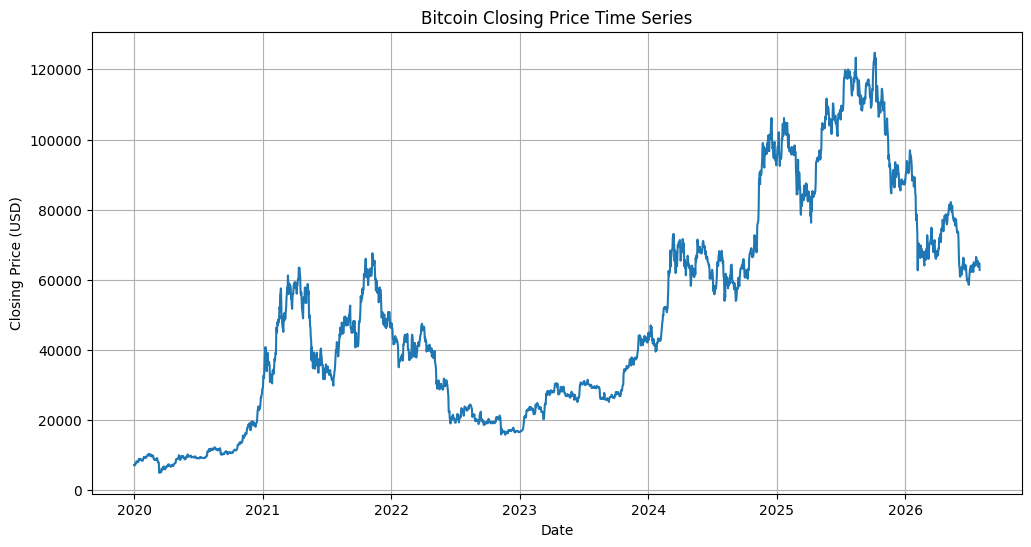

In [ ]:
# Req. 5 (Plot original time series and actual vs predicted values for the test set)

import matplotlib.pyplot as plt
# Import plotting library.

plt.figure(figsize=(12,6))
# Create a larger chart.

plt.plot(df.index, df["Close"])
# Plot Bitcoin closing prices over time.

plt.title("Bitcoin Closing Price Time Series")
# Add chart title.

plt.xlabel("Date")
# Label x-axis.

plt.ylabel("Closing Price (USD)")
# Label y-axis.

plt.grid(True)
# Add grid for easier reading.

plt.show()
# Display the plot.


Plot 2: Actual vs Predicted Values (Test Set)

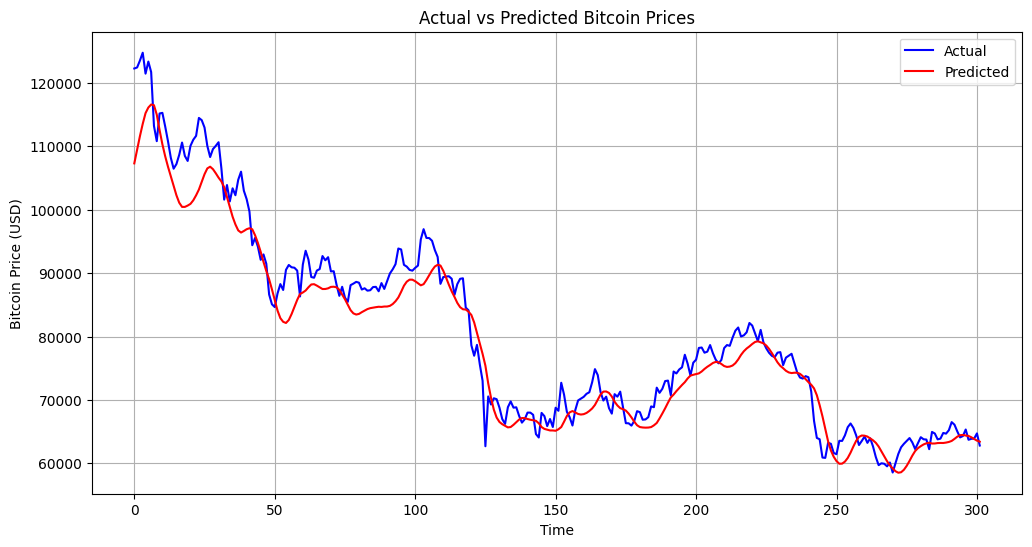

In [20]:
import matplotlib.pyplot as plt
# Import plotting library.

plt.figure(figsize=(12,6))
# Create a larger figure.

plt.plot(y_actual, label="Actual", color="blue")
# Plot actual Bitcoin prices from the test set.

plt.plot(predictions, label="Predicted", color="red")
# Plot LSTM predicted prices.

plt.title("Actual vs Predicted Bitcoin Prices")
# Add chart title.

plt.xlabel("Time")
# Label x-axis.

plt.ylabel("Bitcoin Price (USD)")
# Label y-axis.

plt.legend()
# Show labels for both lines.

plt.grid(True)
# Add grid.

plt.show()
# Display the chart.

Req.6
Interpret the results and discuss how well the model captures trends and seasonality

RMSE (Root Mean Squared Error) = 3958.8041631011642
MAE (Mean Absolute Error) = 3019.776684085265
MAPE (Mean Absolute Percentage Error) = 3.5795266633705665 
(predictions are only 3.58% wrong)

    The average prediction error was approximately $3,020 (MAE), while the RMSE of $3,959 indicates some larger errors occurred but were not frequent. The MAPE of 3.58% shows that the predictions were very close to the actual Bitcoin prices





Using the model forecast the next 60 days price


Bitcoin Price Forecast for the Next 60 Days:

Day 1: $63,157.20
Day 2: $62,891.62
Day 3: $62,623.58
Day 4: $62,356.44
Day 5: $62,092.37
Day 6: $61,832.74
Day 7: $61,578.39
Day 8: $61,329.75
Day 9: $61,087.07
Day 10: $60,850.41
Day 11: $60,619.68
Day 12: $60,394.82
Day 13: $60,175.61
Day 14: $59,961.90
Day 15: $59,753.46
Day 16: $59,550.10
Day 17: $59,351.59
Day 18: $59,157.77
Day 19: $58,968.43
Day 20: $58,783.39
Day 21: $58,602.48
Day 22: $58,425.55
Day 23: $58,252.45
Day 24: $58,083.05
Day 25: $57,917.24
Day 26: $57,754.89
Day 27: $57,595.91
Day 28: $57,440.17
Day 29: $57,287.60
Day 30: $57,138.10
Day 31: $56,991.59
Day 32: $56,847.98
Day 33: $56,707.20
Day 34: $56,569.18
Day 35: $56,433.83
Day 36: $56,301.10
Day 37: $56,170.92
Day 38: $56,043.22
Day 39: $55,917.96
Day 40: $55,795.04
Day 41: $55,674.43
Day 42: $55,556.06
Day 43: $55,439.90
Day 44: $55,325.86
Day 45: $55,213.93
Day 46: $55,104.02
Day 47: $54,996.11
Day 48: $54,890.13
Day 49: $54,786.05
Day 50: $54,683.83
Day 51: $54,5

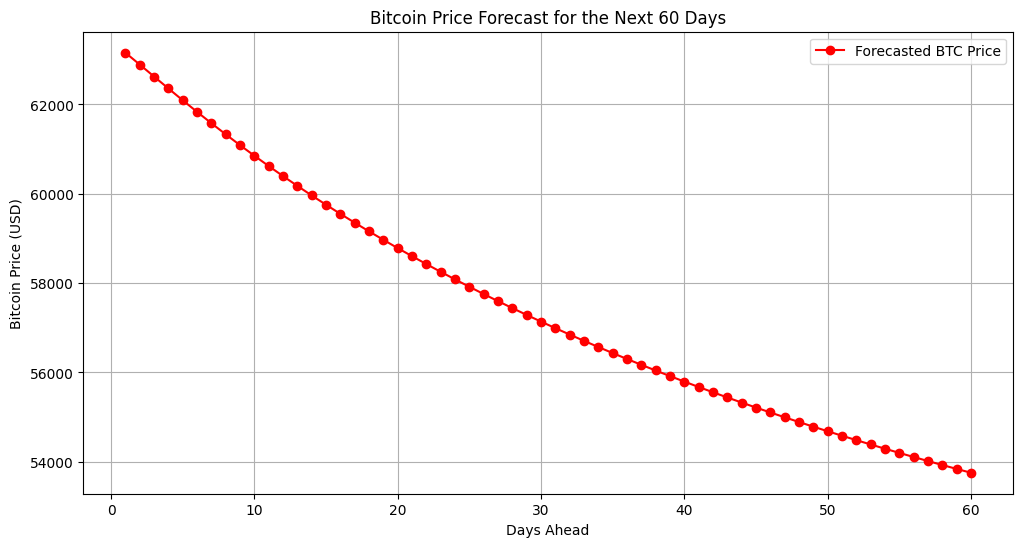

In [23]:
# Forecast Bitcoin Prices for the Next 60 Days

import numpy as np
import matplotlib.pyplot as plt

# Store future predictions
future_predictions = []

# Take the most recent 60 days of scaled data
current_batch = scaled_data[-60:].reshape(1, 60, 1)

# Forecast the next 60 days
for i in range(60):

    # Predict next day's price
    next_prediction = model.predict(current_batch, verbose=0)

    # Save prediction
    future_predictions.append(next_prediction[0, 0])

    # Update the 60-day window
    current_batch = np.append(
        current_batch[:, 1:, :],
        [[[next_prediction[0, 0]]]],
        axis=1
    )

# Convert to NumPy array
future_predictions = np.array(future_predictions).reshape(-1, 1)

# Convert scaled values back to actual BTC prices
future_predictions = scaler.inverse_transform(future_predictions)

# Flatten for easier printing and plotting
future_predictions = future_predictions.flatten()

# Print forecasted prices
print("Bitcoin Price Forecast for the Next 60 Days:\n")

for day, price in enumerate(future_predictions, start=1):
    print(f"Day {day}: ${float(price):,.2f}")

# Plot forecast
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, 61),
    future_predictions,
    marker='o',
    color='red',
    label='Forecasted BTC Price'
)

plt.title("Bitcoin Price Forecast for the Next 60 Days")
plt.xlabel("Days Ahead")
plt.ylabel("Bitcoin Price (USD)")
plt.grid(True)
plt.legend()

plt.show()

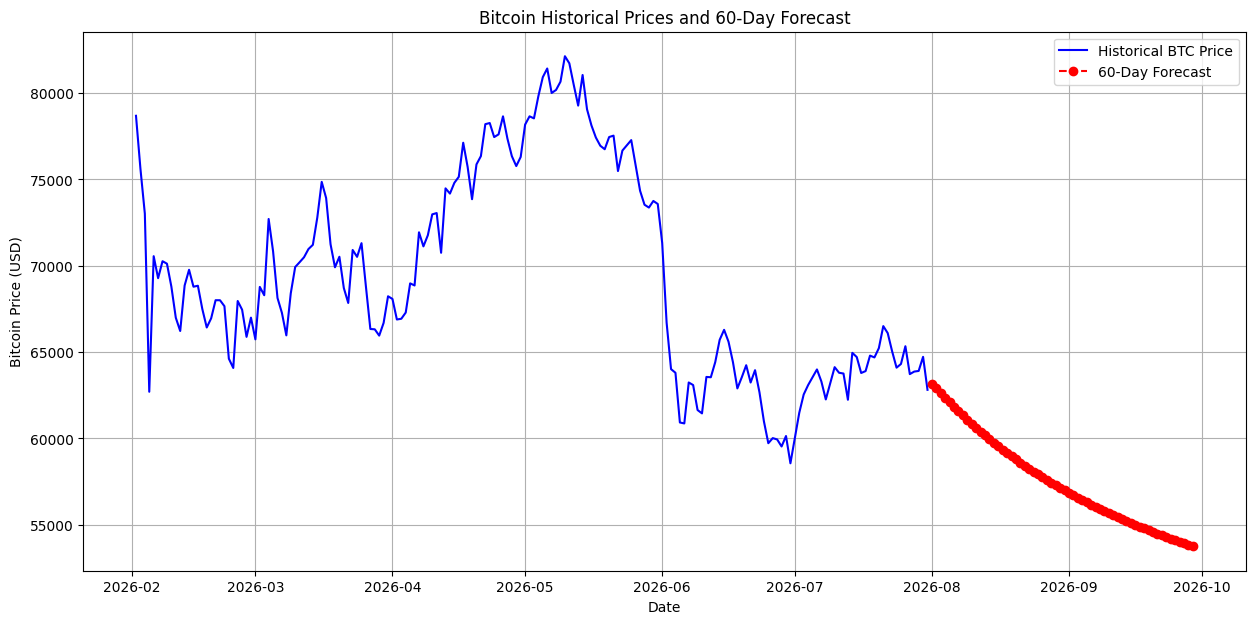

In [24]:
#polting with previous data
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Create future dates
future_dates = pd.date_range(
    start=df.index[-1] + pd.Timedelta(days=1),
    periods=60,
    freq='D'
)

# Plot historical data and forecast
plt.figure(figsize=(15, 7))

# Last 180 days of actual BTC prices
plt.plot(
    df.index[-180:],
    df["Close"][-180:],
    label="Historical BTC Price",
    color="blue"
)

# Forecasted prices
plt.plot(
    future_dates,
    future_predictions,
    label="60-Day Forecast",
    color="red",
    linestyle="--",
    marker="o"
)

plt.title("Bitcoin Historical Prices and 60-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Bitcoin Price (USD)")
plt.legend()
plt.grid(True)

plt.show()